In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns


I imported pandas for working with and analysing data, NumPy for numerical calculations, Matplotlib for creating graphs and visualisations, and Scipy stats for statistical calculations and tests.

In [5]:
df = pd.read_csv("../Data/health_study_dataset.csv")
display(df.head())

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


I used pd.read_csv() to load the CSV file into a DataFrame. Then, I used df.head() to display the first five rows.

In [6]:
df.shape


(799, 9)

It shows the number of rows and columns in the dataset.

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 799 entries, 0 to 798
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           799 non-null    int64  
 1   age          799 non-null    int64  
 2   sex          799 non-null    str    
 3   height       799 non-null    float64
 4   weight       799 non-null    float64
 5   systolic_bp  799 non-null    float64
 6   cholesterol  799 non-null    float64
 7   smoker       799 non-null    str    
 8   disease      799 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.3 KB


I used df.info() to check the dataset structure, column names, data types and missing values.

In [7]:
df.isnull().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

I used `df.isnull().sum()` to check the number of missing values in each column of the dataset.

In [8]:
columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]

statistics = df[columns].agg(
    ["mean", 
     "median",
     "min",
     "max"])

display (statistics)

,age,weight,height,systolic_bp,cholesterol
mean,49.435544,73.410638,171.840926,149.197372,4.928498
median,50.000000,73.200000,171.300000,149.400000,4.970000
min,18.000000,33.700000,144.400000,106.800000,2.500000
max,90.000000,114.400000,200.400000,185.900000,7.880000


First, I select the five columns: age, weight, height, systolic_bp and cholesterol from the dataset. Then calculate the mean , median , minimum and maximum values and then finally display the results.



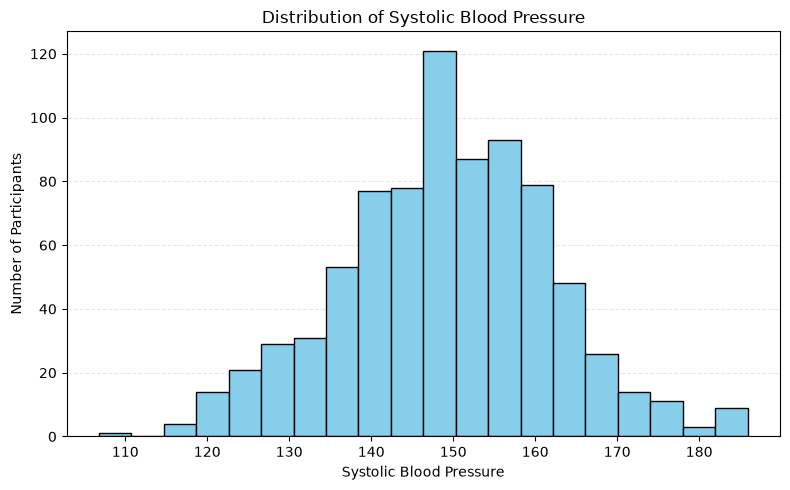

In [9]:
# Create a histogram of systolic blood pressure

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    df["systolic_bp"].dropna(),
    bins=20,
    color="skyblue",
    edgecolor="black"
)

ax.set_title("Distribution of Systolic Blood Pressure")
ax.set_xlabel("Systolic Blood Pressure")
ax.set_ylabel("Number of Participants")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

C:\Users\Dell\AppData\Local\Temp\ipykernel_21280\3200787406.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,


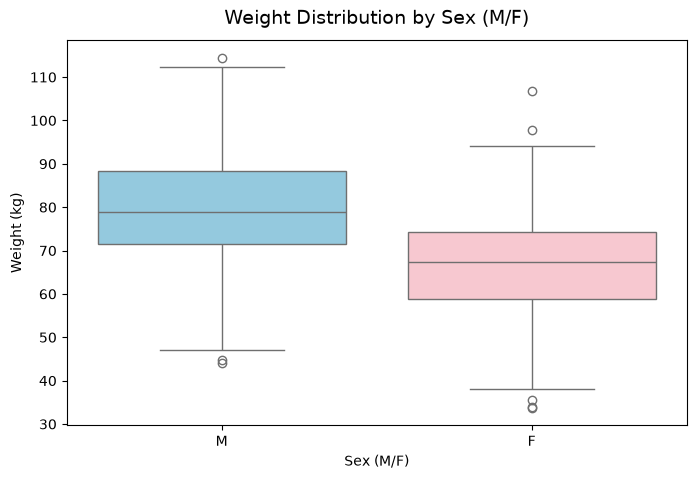

In [13]:
# Create a boxplot showing weight distribution by sex
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=df, 
            x="sex", 
            y="weight", 
            order=["M", "F"], 
            palette={"M": "skyblue", "F": "pink"},)

ax.set_title("Weight Distribution by Sex (M/F)", fontsize=14, pad=12 )
ax.set_xlabel("Sex (M/F)")
ax.set_ylabel("Weight (kg)")

plt.show()

In [18]:
if smoking_percentage["Yes"] > smoking_percentage["No"]:
    print("Smokers have a higher percentage.")
else:
    print("Non-smokers have a higher percentage.")

Non-smokers have a higher percentage.


In [19]:
print(smoking_percentage)

smoker
No     73.341677
Yes    26.658323
Name: proportion, dtype: float64


 I used an if-else condition to compare the percentages of smokers and non-smokers. It checks which group has a higher percentage and prints the result.

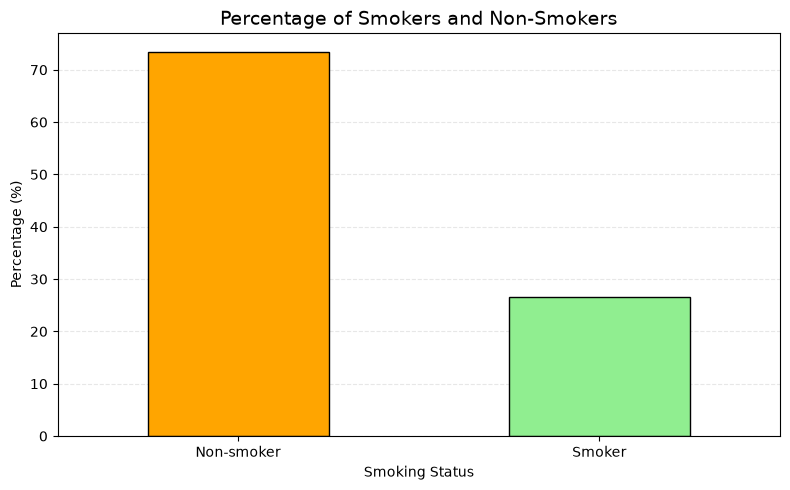

In [20]:
# Create a bar chart showing the percentage of smokers and non-smokers
smoking_percentage = (df["smoker"]
                      .value_counts(normalize=True) * 100
                     )

fig, ax = plt.subplots(figsize=(8, 5))

smoking_percentage.plot(
    kind="bar",
    color=["orange", "lightgreen"],
    edgecolor="black",
    ax=ax
)

ax.set_title("Percentage of Smokers and Non-Smokers", fontsize=14)
ax.set_xlabel("Smoking Status")
ax.set_ylabel("Percentage (%)")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_xticklabels(["Non-smoker", "Smoker"], rotation=0)

plt.tight_layout()
plt.show()



Data Visualization

I have created three different visualizations to understand the health dataset.

The histogram shows the distribution of systolic blood pressure.
The boxplot compares weight between different genders.
The bar chart shows the percentage of smokers and non-smokers.

Visualizations make it easier to identify patterns, differences and possible outliers in the dataset.

In [29]:
df.columns

Index(['id', 'age', 'sex', 'height', 'weight', 'systolic_bp', 'cholesterol',
       'smoker', 'disease'],
      dtype='str')

In [21]:
# Peaple who have the  disease percentage calculated
actual_percentage = df['disease'].mean()
print("Actual:", actual_percentage * 100)


Actual: 5.88235294117647


In [22]:
#Set a random seed 
np.random.seed(42)

simulation = np.random.binomial(
    n=1,
    p=actual_percentage,
    size=1000
)

simulated_percentage = simulation.mean()

print(
    "Simulated disease percentage:",
    simulated_percentage * 100
)

Simulated disease percentage: 5.6000000000000005


In [23]:
# Compare the actual and simulated disease percentages

print(f"Actual disease percentage: {actual_percentage * 100:.2f}%")
print(f"Simulated disease percentage: {simulated_percentage * 100:.2f}%")

difference = abs((actual_percentage * 100) - (simulated_percentage * 100))

print(f"Difference: {difference:.2f} percentage points")

Actual disease percentage: 5.88%
Simulated disease percentage: 5.60%
Difference: 0.28 percentage points


Actual disease proportion:
First, I calculate the actual proportion of people who have the disease in the dataset. Then, I multiply it by 100 to get the percentage. The result is 5.88%.

I use .2f in the f-string to round the displayed result to two decimal places. For example, 5.876% is displayed as 5.88%.


Simulation:
Next, I use NumPy to simulate 1,000 random people with the same disease probability as the real dataset.The simulated disease percentage is 5.60%.


Random seed:
I use np.random.seed(42) to get the same simulation results every time.

Comparison:
Finally, I compare the two percentages. The difference is only 0.28 percentage points. This means the simulated result is close to the actual result.

In [24]:
# Calculate a 95% confidence interval for mean systolic blood pressure

import numpy as np


bp = df["systolic_bp"].dropna()


mean_bp = bp.mean()

std_bp = bp.std()
n = len(bp)

se = std_bp / np.sqrt(n)

lower = mean_bp - 1.96 * se
upper = mean_bp + 1.96 * se

print("Mean systolic blood pressure:", mean_bp)
print("95% Confidence Interval:", lower, "to", upper)

Mean systolic blood pressure: 149.1973717146433
95% Confidence Interval: 148.31048954763182 to 150.0842538816548


Calculate a 95% confidence interval for  systolic blood pressure
First, I remove missing values from the systolic_bp column.

Then:
- Calculate the mean (average) blood pressure.(mean_bp)
- Calculate the standard deviation. I used the variable std_np
- Count the number of people(n).
- Calculate the standard error(se)
- Calculate the 95% confidence interval using 1.96.
Finally, I display the average blood pressure and its 95% confidence interval.


In [25]:
from scipy.stats import ttest_ind

print(df["smoker"].unique())


# Separate smokers and non-smokers
smokers = df[df["smoker"] == "Yes"]["systolic_bp"].dropna() # Yes means 1(smokers) and No means 0 (non smokers)

non_smokers = df[df["smoker"] == "No"]["systolic_bp"].dropna()

# Calculate average blood pressure
print("Smokers mean:", smokers.mean())
print("Non-smokers mean:", non_smokers.mean())

# Perform independent t-test
t_stat, p_value = ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="greater"
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

<StringArray>
['No', 'Yes']
Length: 2, dtype: str
Smokers mean: 149.524882629108
Non-smokers mean: 149.0783276450512
T-statistic: 0.42609977395559384
P-value: 0.3351447960099784


First, I imported ttest_ind from scipy.stats. I used .unique() to check the values in the smoker column. I found that the values are "Yes" and "No", not 1 and 0. This helped me select the correct groups.

Then, I separated the data into two groups: smokers and non-smokers. I selected the systolic_bp column for both groups and used .dropna() to remove missing values.

Next, I calculated and displayed the average blood pressure for both groups to compare them.

After that, I used the ttest_ind() function to compare the two groups. It returned two values: t_stat and p_value.

I set equal_var=False because I did not assume that both groups have the same variance. This is called Welch's t-test.

Finally, I used alternative="greater" because I wanted to test whether smokers have a higher average systolic blood pressure than non-smokers.
